<a href="https://colab.research.google.com/github/Andreewwss/Agenda-U/blob/main/Rese%C3%B1as_Falsas_Amazon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer


nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:

print("1. Carga del dataset y verificación")

df = pd.read_csv("fake reviews dataset.csv")
print("Estructura inicial del DataFrame:")
print(df.info())
print(df.head())

1. Carga del dataset y verificación
Estructura inicial del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  object 
 1   rating    40432 non-null  float64
 2   label     40432 non-null  object 
 3   text_     40432 non-null  object 
dtypes: float64(1), object(3)
memory usage: 1.2+ MB
None
             category  rating label  \
0  Home_and_Kitchen_5     5.0    CG   
1  Home_and_Kitchen_5     5.0    CG   
2  Home_and_Kitchen_5     5.0    CG   
3  Home_and_Kitchen_5     1.0    CG   
4  Home_and_Kitchen_5     5.0    CG   

                                               text_  
0  Love this!  Well made, sturdy, and very comfor...  
1  love it, a great upgrade from the original.  I...  
2  This pillow saved my back. I love the look and...  
3  Missing information on how to use it, but it i...  
4  Very nice set. Goo

In [ ]:
print("2. Definición de variables")
# El dataset contiene: 'category', 'rating', 'label', 'text_'
# Descartaremos 'category' ya que el análisis principal se basa en el texto y el rating.
columnas_utiles = ['text_', 'rating', 'label']
df = df[columnas_utiles]
print("Columnas conservadas:", df.columns.tolist())

2. Definición de variables
Columnas conservadas: ['text_', 'rating', 'label']


In [ ]:
print("3. Validación de tipos y nulos")
print("Nulos antes de limpieza:\n", df.isnull().sum())
# Eliminar filas sin reseña y asegurar que el texto sea tipo string
df = df.dropna(subset=['text_'])
df['text_'] = df['text_'].astype(str)
print("Nulos después de limpieza:\n", df.isnull().sum())

3. Validación de tipos y nulos
Nulos antes de limpieza:
 text_     0
rating    0
label     0
dtype: int64
Nulos después de limpieza:
 text_     0
rating    0
label     0
dtype: int64


In [ ]:
print("4 y 5. Limpieza y Normalización")
def limpiar_texto(texto):
    # Conversión a minúsculas
    texto = texto.lower()
    # Remoción de etiquetas HTML
    texto = re.sub(r'<.*?>', '', texto)
    # Remoción de URLs
    texto = re.sub(r'http\S+|www\S+|https\S+', '', texto, flags=re.MULTILINE)
    # Eliminación de puntuación y caracteres especiales
    texto = re.sub(r'[^\w\s]', '', texto)
    # Eliminación de números
    texto = re.sub(r'\d+', '', texto)
    return texto

4 y 5. Limpieza y Normalización


In [ ]:
df['texto_limpio'] = df['text_'].apply(limpiar_texto)

In [ ]:
print("6 y 7. Procesamiento NLP (Tokens, Stopwords, Lemmas)")
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def procesar_nlp(texto):
    # Tokenización
    tokens = word_tokenize(texto)
    # Filtrado de stopwords
    tokens_filtrados = [word for word in tokens if word not in stop_words]
    # Lematización
    tokens_lematizados = [lemmatizer.lemmatize(word) for word in tokens_filtrados]
    return " ".join(tokens_lematizados)

6 y 7. Procesamiento NLP (Tokens, Stopwords, Lemmas)


In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
df['texto_procesado'] = df['texto_limpio'].apply(procesar_nlp)

8. Análisis exploratorio univariado (EDA)


/tmp/ipykernel_610/2453238704.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='rating', palette='viridis')


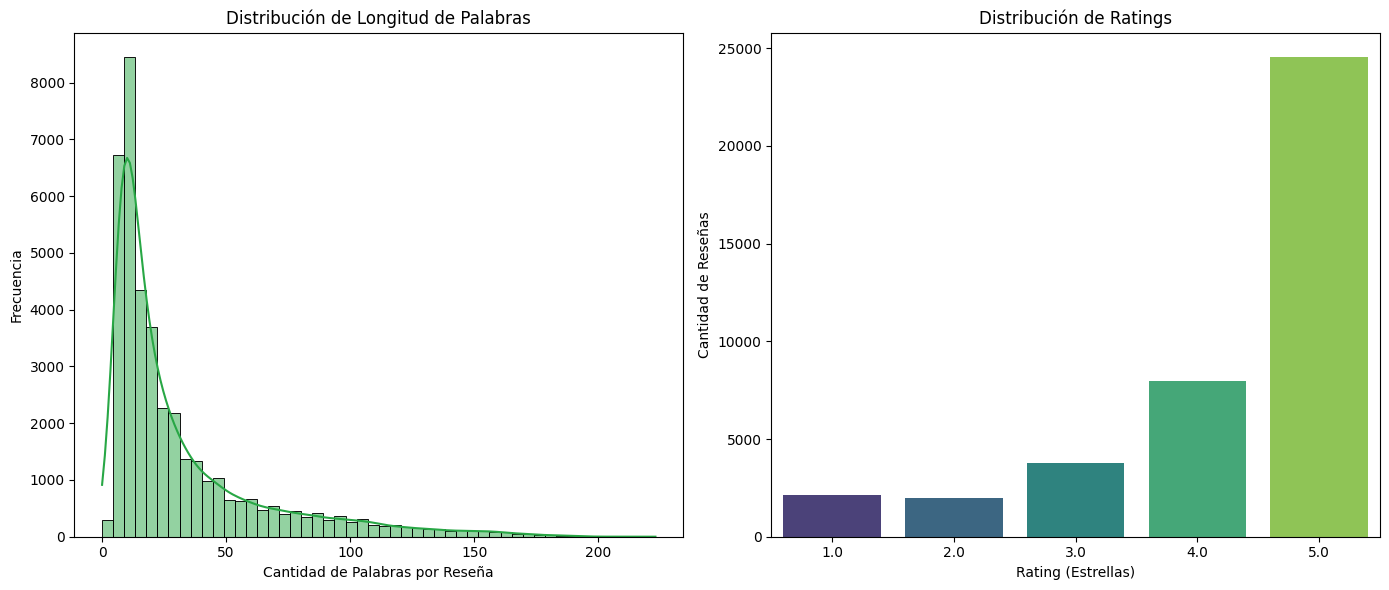

In [ ]:
print("8. Análisis exploratorio univariado (EDA)")
# Cálculo de la longitud de palabras por cada reseña procesada
df['longitud_palabras'] = df['texto_procesado'].apply(lambda x: len(x.split()))

# Configuración del lienzo para las gráficas
plt.figure(figsize=(14, 6))

# Gráfica 1: Distribución de la longitud de palabras
plt.subplot(1, 2, 1)
sns.histplot(df['longitud_palabras'], bins=50, kde=True, color='#28a745')
plt.title('Distribución de Longitud de Palabras')
plt.xlabel('Cantidad de Palabras por Reseña')
plt.ylabel('Frecuencia')

# Gráfica 2: Distribución de los ratings
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='rating', palette='viridis')
plt.title('Distribución de Ratings')
plt.xlabel('Rating (Estrellas)')
plt.ylabel('Cantidad de Reseñas')

plt.tight_layout()
plt.show()

In [ ]:
df.to_csv("clean_fake_reviews.csv", index=False)
print("Archivo 'clean_fake_reviews.csv' exportado con éxito.")

Archivo 'clean_fake_reviews.csv' exportado con éxito.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob


# 1. CARGAR EL DATASET YA LIMPIO
print("1. Cargando el dataset limpio...")
df = pd.read_csv("clean_fake_reviews.csv")

df = df.dropna(subset=['texto_limpio'])
df['texto_limpio'] = df['texto_limpio'].astype(str)

if 'longitud_palabras' not in df.columns:
    df['longitud_palabras'] = df['texto_limpio'].apply(lambda x: len(x.split()))

1. Cargando el dataset limpio...


In [ ]:
# 2. ANÁLISIS DE SENTIMIENTO (Polaridad y Subjetividad)
print("2. Calculando polaridad y subjetividad de sentimiento...")
df['polaridad'] = df['texto_limpio'].apply(lambda x: TextBlob(x).sentiment.polarity)
df['subjetividad'] = df['texto_limpio'].apply(lambda x: TextBlob(x).sentiment.subjectivity)

2. Calculando polaridad y subjetividad de sentimiento...


3. Generando Matriz de Correlación...


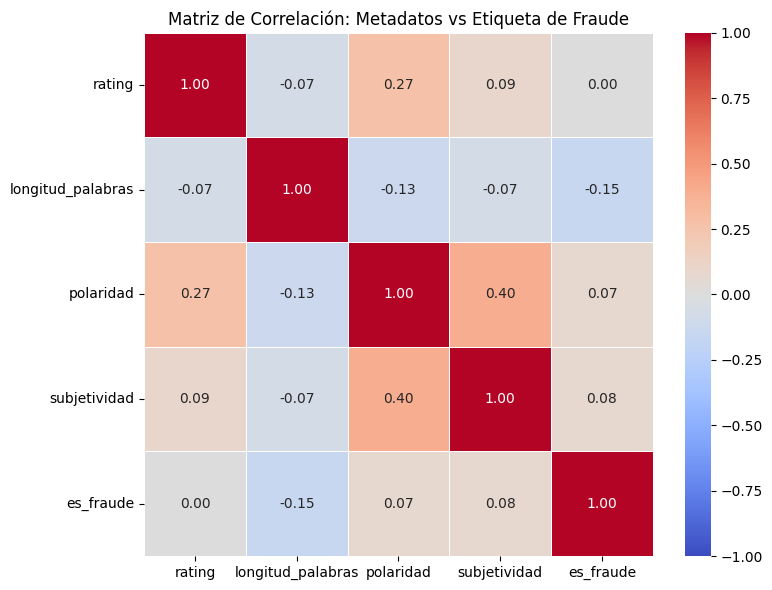

In [ ]:
# 3. MATRIZ DE CORRELACIÓN
print("3. Generando Matriz de Correlación...")
# Convertimos la etiqueta 'CG' (Fraude) en 1 y 'OR' (Original) en 0
df['es_fraude'] = np.where(df['label'] == 'CG', 1, 0)

cols_numericas = ['rating', 'longitud_palabras', 'polaridad', 'subjetividad', 'es_fraude']
corr_matrix = df[cols_numericas].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación: Metadatos vs Etiqueta de Fraude')
plt.tight_layout()
plt.savefig('matriz_correlacion.png')
plt.show()

In [ ]:
print("4. Exportando dataset para el modelado...")
df.to_csv("dataset_final_modelado.csv", index=False)
print("¡ÉXITO! Toda la Fase 2 está completada.")

4. Exportando dataset para el modelado...
¡ÉXITO! Toda la Fase 2 está completada.


## Bloque 1: Vectorización TF-IDF y Preparación de Matrices
Este código toma el texto limpio y lo convierte en números (TF-IDF), escala los metadatos numéricos (para que variables grandes no opaquen a las pequeñas) y une todo en una sola matriz dispersa. También divide los datos en entrenamiento y prueba.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, csr_matrix

print("--- Tareas T-31 a T-35: Vectorización y Partición de Datos ---")

# 1. Cargar el dataset final exportado en la Fase 2
df = pd.read_csv("dataset_final_modelado.csv")
df = df.dropna(subset=['texto_procesado']) # Asegurar que no haya nulos

# Definir variables predictoras numéricas y el texto
cols_numericas = ['rating', 'longitud_palabras', 'polaridad', 'subjetividad']
X_texto = df['texto_procesado']
X_num = df[cols_numericas]
y = df['es_fraude']

# 2. Partición estratificada (T-34 y T-35) para mantener la proporción de fraudes
X_text_train, X_text_test, X_num_train, X_num_test, y_train, y_test = train_test_split(
    X_texto, X_num, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Vectorización TF-IDF con límite de vocabulario (T-31)
tfidf = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), min_df=5)
X_text_train_tfidf = tfidf.fit_transform(X_text_train)
X_text_test_tfidf = tfidf.transform(X_text_test)

# 4. Escalamiento de metadatos y concatenación (T-33)
scaler = StandardScaler()
X_num_train_scaled = scaler.fit_transform(X_num_train)
X_num_test_scaled = scaler.transform(X_num_test)

# Unir matriz de texto con matriz numérica
X_train_final = hstack([X_text_train_tfidf, csr_matrix(X_num_train_scaled)]).tocsr()
X_test_final = hstack([X_text_test_tfidf, csr_matrix(X_num_test_scaled)]).tocsr()

print(f"Dimensiones matriz de entrenamiento: {X_train_final.shape}")
print(f"Dimensiones matriz de prueba: {X_test_final.shape}")

--- Tareas T-31 a T-35: Vectorización y Partición de Datos ---
Dimensiones matriz de entrenamiento: (32344, 2004)
Dimensiones matriz de prueba: (8087, 2004)


## Bloque 2: Entrenamiento y Evaluación de Algoritmos

Aquí se entrenan los tres algoritmos propuestos en el documento: Regresión Logística (baseline), Random Forest y Gradient Boosting. Luego, se calculan las métricas robustas al desbalance (F1-Score y ROC-AUC).



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print("--- Tareas T-36 a T-39: Entrenamiento y Métricas ---")

# Diccionario de modelos con hiperparámetros iniciales
modelos = {
    "Regresión Logística (Baseline)": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    # Usamos HistGradientBoosting porque es mucho más rápido para matrices grandes
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42)
}

resultados = []

# Entrenar y evaluar cada modelo
for nombre, modelo in modelos.items():
    print(f"Entrenando {nombre}...")

    # HistGradientBoosting requiere matrices densas, los otros soportan dispersas
    if nombre == "Gradient Boosting":
        modelo.fit(X_train_final.toarray(), y_train)
        y_pred = modelo.predict(X_test_final.toarray())
        y_prob = modelo.predict_proba(X_test_final.toarray())[:, 1]
    else:
        modelo.fit(X_train_final, y_train)
        y_pred = modelo.predict(X_test_final)
        y_prob = modelo.predict_proba(X_test_final)[:, 1]

    # Calcular métricas
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)

    resultados.append({
        "Modelo": nombre,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc
    })

# Mostrar resultados en formato tabla
df_resultados = pd.DataFrame(resultados)
print("\n--- Resultados de Evaluación ---")
display(df_resultados)

--- Tareas T-36 a T-39: Entrenamiento y Métricas ---
Entrenando Regresión Logística (Baseline)...
Entrenando Random Forest...
Entrenando Gradient Boosting...

--- Resultados de Evaluación ---


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística (Baseline),0.875850,0.876954,0.874351,0.875650,0.949441
1,Random Forest,0.861630,0.873531,0.845659,0.859369,0.935356
2,Gradient Boosting,0.865587,0.876081,0.851595,0.863665,0.946199


## Bloque 3: Visualización de Curvas ROC y Matrices de Confusión


Genera las gráficas visuales que necesitan para justificar el desempeño del modelo en el informe final.

--- Tarea T-40: Análisis ROC-AUC y Matrices de Confusión ---


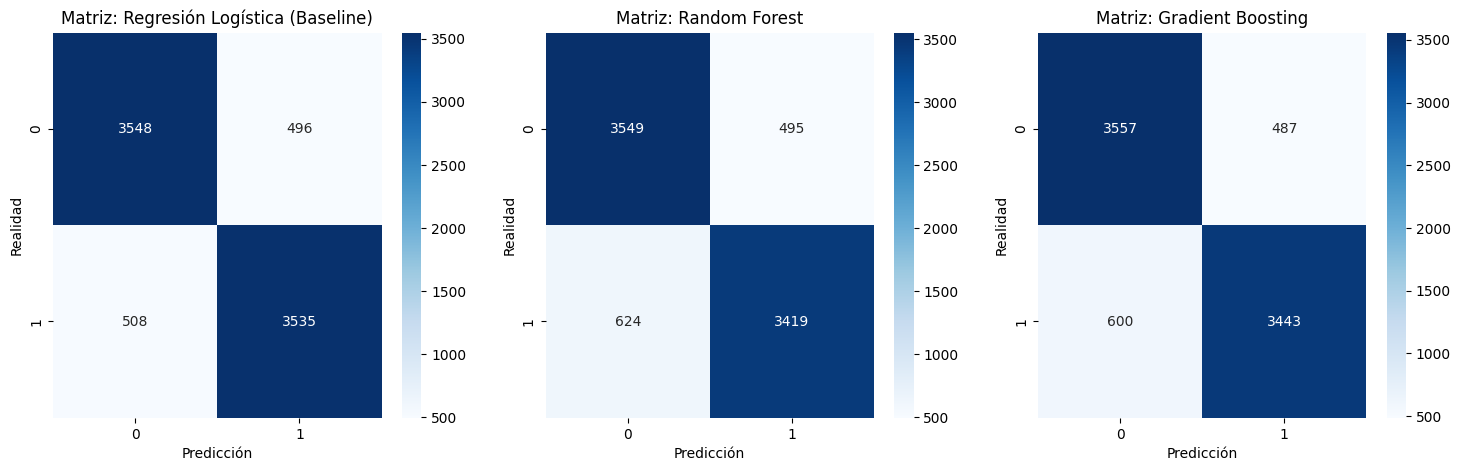

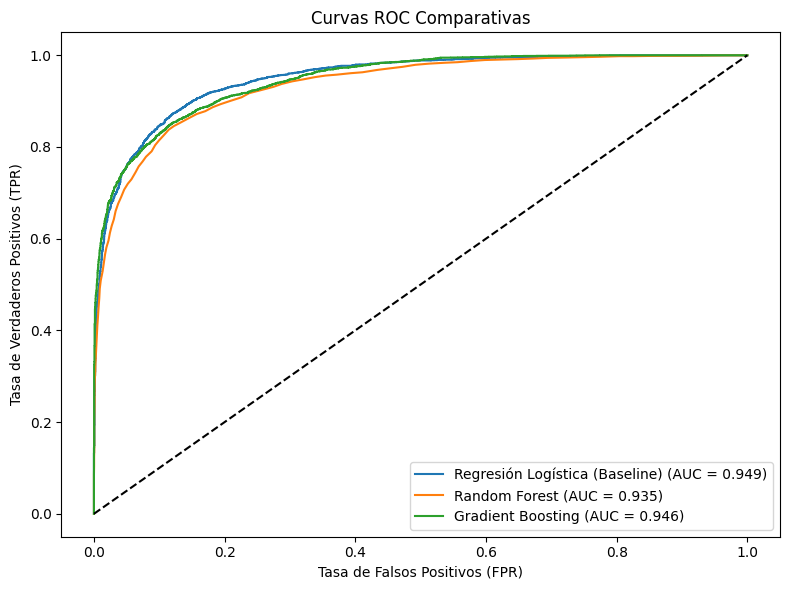

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

print("--- Tarea T-40: Análisis ROC-AUC y Matrices de Confusión ---")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig_roc, ax_roc = plt.subplots(figsize=(8, 6))

for idx, (nombre, modelo) in enumerate(modelos.items()):
    # Predicciones
    if nombre == "Gradient Boosting":
        y_pred = modelo.predict(X_test_final.toarray())
        y_prob = modelo.predict_proba(X_test_final.toarray())[:, 1]
    else:
        y_pred = modelo.predict(X_test_final)
        y_prob = modelo.predict_proba(X_test_final)[:, 1]

    # Matriz de confusión
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx])
    axes[idx].set_title(f'Matriz: {nombre}')
    axes[idx].set_xlabel('Predicción')
    axes[idx].set_ylabel('Realidad')

    # Curva ROC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax_roc.plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc_score(y_test, y_prob):.3f})')

# Ajustes de Curva ROC
ax_roc.plot([0, 1], [0, 1], 'k--')
ax_roc.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax_roc.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax_roc.set_title('Curvas ROC Comparativas')
ax_roc.legend()

plt.tight_layout()
plt.show()

## Bloque 4: Interpretabilidad SHAP

Este bloque analiza por qué el modelo tomó la decisión usando SHAP values, lo cual demuestra que el sistema no es una "caja negra". Como SHAP es pesado, lo aplicaremos al modelo de Regresión Logística (o Random Forest) usando una muestra pequeña para que no se bloquee el Colab.

/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


--- Tarea T-42: Interpretabilidad y relevancia de características con SHAP ---


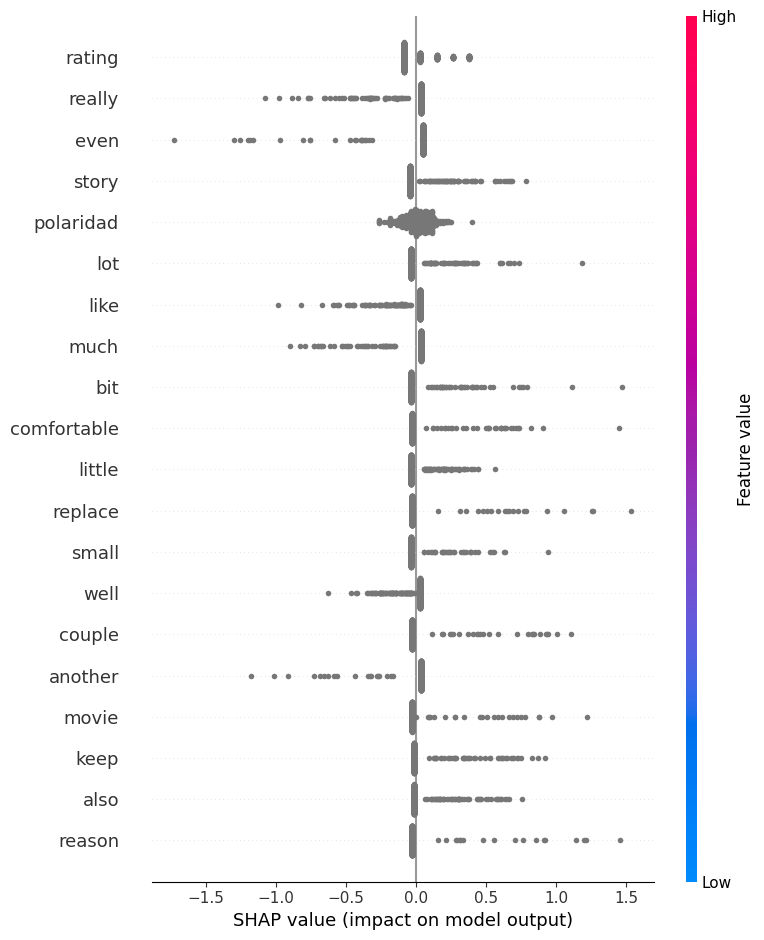

In [ ]:
# Instalar SHAP si no lo tienen (correr en una celda separada: !pip install shap)
import shap

print("--- Tarea T-42: Interpretabilidad y relevancia de características con SHAP ---")

# Para este ejemplo extraemos los nombres de las columnas
nombres_features = tfidf.get_feature_names_out().tolist() + cols_numericas
modelo_explicar = modelos["Regresión Logística (Baseline)"]

# Usamos un explicador lineal para mayor velocidad
explainer = shap.LinearExplainer(modelo_explicar, X_train_final, feature_perturbation="interventional")

# Tomamos una muestra de 500 registros para no agotar la RAM
X_test_sample = X_test_final[:500]
shap_values = explainer.shap_values(X_test_sample)

# Generar gráfico resumen
shap.summary_plot(shap_values, X_test_sample, feature_names=nombres_features)

## Bloque Final de Código: Optimización y Exportación

In [ ]:
import joblib
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_curve

print("--- Tarea T-41: Optimización de hiperparámetros (GridSearch) ---")

# Vamos a optimizar el Random Forest como ejemplo (es estable y rápido de afinar)
rf_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
grid_search = GridSearchCV(estimator=rf_base, param_grid=rf_grid, cv=3, scoring='f1', n_jobs=-1, verbose=1)

# Entrenamos el GridSearch
print("Buscando los mejores parámetros para Random Forest...")
grid_search.fit(X_train_final, y_train)
mejor_modelo = grid_search.best_estimator_

print(f"Mejores hiperparámetros encontrados: {grid_search.best_params_}")


print("\n--- Tarea T-44: Calibración de probabilidad y tuning de umbral ---")

# Obtenemos las probabilidades del mejor modelo
y_prob_best = mejor_modelo.predict_proba(X_test_final)[:, 1]

# Calculamos la curva Precision-Recall para encontrar el umbral óptimo
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_best)

# Buscamos el umbral que maximice el F1-Score (equilibrio entre precisión y exhaustividad)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8) # 1e-8 evita división por cero
mejor_indice = np.argmax(f1_scores)
umbral_optimo = thresholds[mejor_indice]

print(f"El umbral óptimo de corte es: {umbral_optimo:.3f} (Por defecto es 0.500)")
print(f"F1-Score máximo con este umbral: {f1_scores[mejor_indice]:.3f}")


print("\n--- Tarea T-45: Selección definitiva y congelamiento del algoritmo ganador ---")

# Exportamos el modelo ganador y el vectorizador para que puedan ser usados en una API o App externa
joblib.dump(mejor_modelo, 'modelo_fraude_optimizado.pkl')
joblib.dump(tfidf, 'vectorizador_tfidf.pkl')
joblib.dump(scaler, 'escalador_numerico.pkl')

print("¡Modelo congelado y exportado con éxito!")
print("Archivos generados: 'modelo_fraude_optimizado.pkl', 'vectorizador_tfidf.pkl', 'escalador_numerico.pkl'")

--- Tarea T-41: Optimización de hiperparámetros (GridSearch) ---
Buscando los mejores parámetros para Random Forest...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Mejores hiperparámetros encontrados: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}

--- Tarea T-44: Calibración de probabilidad y tuning de umbral ---
El umbral óptimo de corte es: 0.476 (Por defecto es 0.500)
F1-Score máximo con este umbral: 0.864

--- Tarea T-45: Selección definitiva y congelamiento del algoritmo ganador ---
¡Modelo congelado y exportado con éxito!
Archivos generados: 'modelo_fraude_optimizado.pkl', 'vectorizador_tfidf.pkl', 'escalador_numerico.pkl'
